Install Packages

In [1]:
%pip install numpy pandas seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.


Import Packages

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

SLA Settings

In [3]:
# SLA thresholds in hours. Change them here and re-run the notebook.
FIRST_RESPONSE_SLA_HOURS = 4
RESOLUTION_SLA_HOURS = 24
# NOTE: the file has no ticket-created timestamp, so the time to FIRST response cannot be measured.
# The SLA flag below therefore uses the resolution threshold only (see the New Columns cell).

Loading the Data

In [4]:
df = pd.read_csv('archive/customer_support_tickets.csv')
df.head()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


Shape and Info

In [5]:
print(df.shape)
print("-"*30)
df.info()

(8469, 17)
------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   str    
 2   Customer Email                8469 non-null   str    
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   str    
 5   Product Purchased             8469 non-null   str    
 6   Date of Purchase              8469 non-null   str    
 7   Ticket Type                   8469 non-null   str    
 8   Ticket Subject                8469 non-null   str    
 9   Ticket Description            8469 non-null   str    
 10  Ticket Status                 8469 non-null   str    
 11  Resolution                    2769 non-null   str    
 12  Ticket Priority               8

Summary Statistics

In [6]:
df.describe(include='all')

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
count,8469.000000,8469,8469,8469.000000,8469,8469,8469,8469,8469,8469,8469,2769,8469,8469,5650,2769,2769.000000
unique,NaN,8028,8320,NaN,3,42,730,5,16,8077,3,2769,4,4,5470,2728,NaN
top,NaN,Michael Garcia,asmith@example.com,NaN,Male,Canon EOS,2020-10-21,Refund request,Refund request,I'm having an issue with the {product_purchase...,Pending Customer Response,Case maybe show recently my computer follow.,Medium,Email,2023-06-01 01:21:19,2023-06-01 17:14:42,NaN
freq,NaN,5,4,NaN,2896,240,24,1752,576,25,2881,1,2192,2143,3,3,NaN
mean,4235.000000,NaN,NaN,44.026804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.991333
std,2444.934048,NaN,NaN,15.296112,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.407016
min,1.000000,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
25%,2118.000000,NaN,NaN,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000
50%,4235.000000,NaN,NaN,44.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000
75%,6352.000000,NaN,NaN,57.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000


Duplicates and Unique ID

In [7]:
print('Duplicate rows:', df.duplicated().sum())
print('Ticket ID is unique:', df['Ticket ID'].is_unique)
# Same ticket entered twice under different IDs?
print('Duplicate rows ignoring Ticket ID:', df.duplicated(subset=df.columns.drop('Ticket ID')).sum())
# Repeat customers are normal, so this is only for information
print('Emails that appear more than once:', df['Customer Email'].duplicated().sum())

Duplicate rows: 0
Ticket ID is unique: True
Duplicate rows ignoring Ticket ID: 0
Emails that appear more than once: 149


Missing Values

In [8]:
missing = pd.DataFrame({
    'missing': df.isna().sum(),
    'pct': (df.isna().mean() * 100).round(2)
})
missing = missing[missing['missing'] > 0].sort_values('missing', ascending=False)
print(missing)

rows_missing = df.isna().any(axis=1).sum()
print('\nRows with at least one missing value:', rows_missing, f'({rows_missing / len(df) * 100:.1f}%)')

                              missing    pct
Resolution                       5700  67.30
Time to Resolution               5700  67.30
Customer Satisfaction Rating     5700  67.30
First Response Time              2819  33.29

Rows with at least one missing value: 5700 (67.3%)


Rows With Any Missing Value

In [9]:
df[df.isna().any(axis=1)].head()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
5,6,Rebecca Fleming,sheenasmith@example.com,53,Male,Microsoft Office,2020-07-28,Cancellation request,Payment issue,I'm facing a problem with my {product_purchase...,Open,NaN,Low,Social media,NaN,NaN,NaN
6,7,Jacqueline Wright,donaldkeith@example.org,24,Other,Microsoft Surface,2020-02-23,Product inquiry,Refund request,I'm unable to access my {product_purchased} ac...,Open,NaN,Critical,Social media,NaN,NaN,NaN
7,8,Denise Lee,joelwilliams@example.com,23,Male,Philips Hue Lights,2020-08-09,Refund request,Battery life,I'm having an issue with the {product_purchase...,Open,NaN,Critical,Social media,NaN,NaN,NaN


Value Counts For Every Column

In [10]:
for col in df.columns.drop('Ticket ID'):
    print(f'===== {col} ({df[col].nunique()} unique) =====')
    print(df[col].value_counts(dropna=False).head(8))
    print('--' * 20)

===== Customer Name (8028 unique) =====
Customer Name
Michael Garcia       5
James Smith          5
David Smith          4
Steven Johnson       4
Christopher Jones    4
Joseph Brown         4
Daniel Williams      4
Rebecca Smith        4
Name: count, dtype: int64
----------------------------------------
===== Customer Email (8320 unique) =====
Customer Email
asmith@example.com              4
bsmith@example.com              4
drodriguez@example.com          3
asmith@example.org              3
hsmith@example.org              3
elizabethjenkins@example.com    3
michael41@example.net           3
rodriguezeric@example.net       3
Name: count, dtype: int64
----------------------------------------
===== Customer Age (53 unique) =====
Customer Age
52    186
56    182
27    180
24    180
34    177
59    177
44    173
20    173
Name: count, dtype: int64
----------------------------------------
===== Customer Gender (3 unique) =====
Customer Gender
Male      2896
Female    2887
Other     2686
Nam

How we fill the gaps

Where are the gaps? Missing values against Ticket Status

In [11]:
gap_cols = ['Resolution', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']
# Number of missing values in each gap column, split by status
print(df[gap_cols].isna().groupby(df['Ticket Status']).sum())
print('\nTickets per status:')
print(df['Ticket Status'].value_counts())

                           Resolution  First Response Time  \
Ticket Status                                                
Closed                              0                    0   
Open                             2819                 2819   
Pending Customer Response        2881                    0   

                           Time to Resolution  Customer Satisfaction Rating  
Ticket Status                                                                
Closed                                      0                             0  
Open                                     2819                          2819  
Pending Customer Response                2881                          2881  

Tickets per status:
Ticket Status
Pending Customer Response    2881
Open                         2819
Closed                       2769
Name: count, dtype: int64


Numeric gap columns: mean vs median vs skew

In [12]:
for col in ['Customer Satisfaction Rating', 'Customer Age']:
    print(f'{col}: mean {df[col].mean():.2f} | median {df[col].median()} | skew {df[col].skew():.2f}')
print()
print(df['Customer Satisfaction Rating'].value_counts(dropna=False).sort_index())

Customer Satisfaction Rating: mean 2.99 | median 3.0 | skew 0.01
Customer Age: mean 44.03 | median 44.0 | skew -0.02

Customer Satisfaction Rating
1.0     553
2.0     549
3.0     580
4.0     543
5.0     544
NaN    5700
Name: count, dtype: int64


Is a Missing Value Informative About the Target (Closed)?

In [13]:
closed = (df['Ticket Status'] == 'Closed')
for col in gap_cols:
    print(f'{col}')
    print('   Closed rate when present:', round(closed[df[col].notna()].mean() * 100, 1), '%')
    print('   Closed rate when missing:', round(closed[df[col].isna()].mean() * 100, 1), '%')

Resolution
   Closed rate when present: 100.0 %
   Closed rate when missing: 0.0 %
First Response Time
   Closed rate when present: 49.0 %
   Closed rate when missing: 0.0 %
Time to Resolution
   Closed rate when present: 100.0 %
   Closed rate when missing: 0.0 %
Customer Satisfaction Rating
   Closed rate when present: 100.0 %
   Closed rate when missing: 0.0 %


**Decision on the gaps**

- Every missing value is *structural*, not random: Resolution, Time to Resolution and Satisfaction are filled only for Closed tickets, and First Response Time is empty only for Open tickets.
- A missing value therefore tells us the status directly. This is **target leakage**, so these columns are never used to explain the Closed target.
- Filling them (mean, median or mode) would invent resolutions and ratings for tickets that were never resolved, so they stay as NaN. Power BI shows them as blanks.
- Satisfaction (4-5 = satisfied) is analysed separately on Closed tickets only.
- No rows are dropped.

Clean The Data

In [14]:
rows_before = len(df)

# Column names: spaces -> underscores (easier in code and in Power BI)
df.columns = df.columns.str.replace(' ', '_')

# Remove stray spaces in text columns
text_cols = ['Customer_Name', 'Customer_Email', 'Customer_Gender', 'Product_Purchased', 'Ticket_Type',
             'Ticket_Subject', 'Ticket_Description', 'Ticket_Status', 'Resolution', 'Ticket_Priority',
             'Ticket_Channel']
for col in text_cols:
    df[col] = df[col].str.strip()

# Every description still holds the raw template tag {product_purchased}: fill in the real product
df['Ticket_Description'] = [d.replace('{product_purchased}', p)
                            for d, p in zip(df['Ticket_Description'], df['Product_Purchased'])]

# Text -> dates
for col in ['Date_of_Purchase', 'First_Response_Time', 'Time_to_Resolution']:
    df[col] = pd.to_datetime(df[col])

# Sanity checks (nothing is changed here, we only look)
print('Customer_Age range:', df['Customer_Age'].min(), 'to', df['Customer_Age'].max())
print('Tickets answered before the product was bought:',
      (df['First_Response_Time'].dt.normalize() < df['Date_of_Purchase']).sum())
print('Placeholders left in descriptions:', df['Ticket_Description'].str.contains('{product_purchased}', regex=False).sum())
print('Missing values left (structural, kept on purpose):', df.isna().sum().sum())
print('Rows before / after:', rows_before, '/', len(df), '-> rows dropped:', rows_before - len(df))

Customer_Age range: 18 to 70
Tickets answered before the product was bought: 0
Placeholders left in descriptions: 0
Missing values left (structural, kept on purpose): 19919
Rows before / after: 8469 / 8469 -> rows dropped: 0


New Columns

In [15]:
# --- Target: 1 = Closed, 0 = Open or Pending Customer Response ---
df['Closed'] = (df['Ticket_Status'] == 'Closed').astype(int)
df['Closed_Label'] = df['Closed'].map({1: 'Closed', 0: 'Not Closed'})

# --- Resolution duration in hours (first response -> resolution) ---
hours = (df['Time_to_Resolution'] - df['First_Response_Time']).dt.total_seconds() / 3600
df['invalid_duration'] = (hours < 0).astype(int)      # resolved BEFORE the first response: impossible
df['resolution_hours'] = hours.where(hours >= 0)      # invalid or missing -> NaN (timestamps are kept)

# --- SLA flag with three states ---
# Unknown when the duration is NaN (not closed, or invalid timestamps).
# Only the resolution threshold can be tested: there is no ticket-created time to measure the first response.
df['SLA_Status'] = np.select(
    [df['resolution_hours'].isna(), df['resolution_hours'] > RESOLUTION_SLA_HOURS],
    ['Unknown', 'Violated'],
    default='Within SLA')

# --- Date parts of the purchase date (known for every ticket) ---
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['Purchase_Year'] = df['Date_of_Purchase'].dt.year
df['Purchase_Quarter'] = 'Q' + df['Date_of_Purchase'].dt.quarter.astype(str)
df['Purchase_Month'] = df['Date_of_Purchase'].dt.month
df['Purchase_Weekday'] = pd.Categorical(df['Date_of_Purchase'].dt.day_name(), categories=day_order, ordered=True)

# --- Product age: days from purchase to a FIXED reference date (first day of the ticket log) ---
# A fixed date is used so the column exists for every ticket (first response time is missing for Open tickets).
ref_date = df['First_Response_Time'].min().normalize()
df['Product_Age_Days'] = (ref_date - df['Date_of_Purchase']).dt.days

# --- Date parts of the first response (empty for Open tickets, so NOT used to explain the target) ---
df['has_first_response'] = df['First_Response_Time'].notna().astype(int)
df['Response_Hour'] = df['First_Response_Time'].dt.hour
df['Response_Weekday'] = df['First_Response_Time'].dt.day_name()

# --- Satisfaction (closed tickets only, NaN otherwise) ---
df['Satisfied'] = (df['Customer_Satisfaction_Rating'] >= 4).astype(float).where(df['Customer_Satisfaction_Rating'].notna())

print('Shape:', df.shape)
print('Reference date for Product_Age_Days:', ref_date.date())
print('Closed rate:', df['Closed'].mean().round(3))
print('\nInvalid durations (resolved before first response):', df['invalid_duration'].sum(),
      'of', df['Time_to_Resolution'].notna().sum(), 'closed tickets')
print('Valid resolution_hours:', df['resolution_hours'].notna().sum())
print('\nSLA status:')
print(df['SLA_Status'].value_counts())
print('\nLongest valid resolution:', round(df['resolution_hours'].max(), 2), 'hours (SLA limit', RESOLUTION_SLA_HOURS, ')')

Shape: (8469, 31)
Reference date for Product_Age_Days: 2023-05-31
Closed rate: 0.327

Invalid durations (resolved before first response): 1365 of 2769 closed tickets
Valid resolution_hours: 1404

SLA status:
SLA_Status
Unknown       7065
Within SLA    1404
Name: count, dtype: int64

Longest valid resolution: 23.47 hours (SLA limit 24 )


Skew Of Every Numeric Column

In [16]:
num = df.select_dtypes('number').drop(columns=['Ticket_ID'])   # Ticket_ID is just a label
print(num.skew().round(2).sort_values(ascending=False))

invalid_duration                1.84
Closed                          0.74
resolution_hours                0.70
Satisfied                       0.44
Customer_Satisfaction_Rating    0.01
Product_Age_Days                0.00
Purchase_Year                   0.00
Response_Hour                  -0.01
Purchase_Month                 -0.01
Customer_Age                   -0.02
has_first_response             -0.71
dtype: float64


Log Columns

In [17]:
# Measurement columns we might transform (flags and 1-5 ratings are not measurements)
measures = ['Customer_Age', 'Product_Age_Days', 'resolution_hours']

# Rule: take the log only when the column is clearly skewed (|skew| > 0.5)
# log1p handles the zero-hour resolutions
log_cols = [c for c in measures if abs(df[c].skew()) > 0.5]
for col in log_cols:
    df['log_' + col] = np.log1p(df[col])

for col in measures:
    if col in log_cols:
        print(f'{col}: skew {df[col].skew():.2f} -> {df["log_" + col].skew():.2f}')
    else:
        print(f'{col}: skew {df[col].skew():.2f} -> already symmetric, no log needed')

Customer_Age: skew -0.02 -> already symmetric, no log needed
Product_Age_Days: skew 0.00 -> already symmetric, no log needed
resolution_hours: skew 0.70 -> -0.44


Outliers (IQR 1.5x rule)

In [18]:
for col in measures:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n = ((df[col] < lower) | (df[col] > upper)).sum()
    n_valid = df[col].notna().sum()
    print(f'{col}: {n} outliers ({n / n_valid * 100:.1f}% of {n_valid} values), bounds = {lower:.2f} to {upper:.2f}')

Customer_Age: 0 outliers (0.0% of 8469 values), bounds = -8.00 to 96.00
Product_Age_Days: 0 outliers (0.0% of 8469 values), bounds = 153.00 to 1609.00
resolution_hours: 0 outliers (0.0% of 1404 values), bounds = -9.53 to 23.89


Boxplots, raw vs log

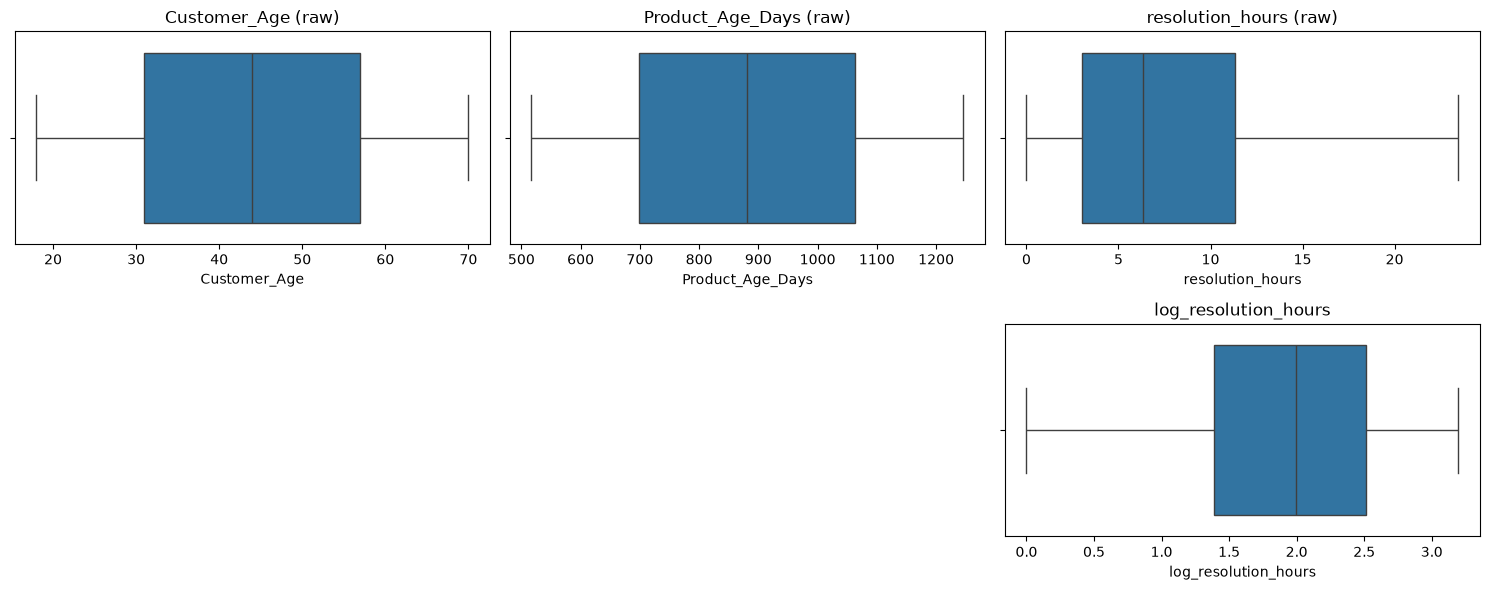

In [19]:
fig, axes = plt.subplots(2, len(measures), figsize=(5 * len(measures), 6))
for i, col in enumerate(measures):
    sns.boxplot(x=df[col], ax=axes[0, i])
    axes[0, i].set_title(col + ' (raw)')
    if col in log_cols:
        sns.boxplot(x=df['log_' + col], ax=axes[1, i])
        axes[1, i].set_title('log_' + col)
    else:
        axes[1, i].axis('off')     # no log version for this column
plt.tight_layout()
plt.show()

Target Balance

Ticket_Status
Pending Customer Response    2881
Open                         2819
Closed                       2769
Name: count, dtype: int64

Closed_Label
Not Closed    5700
Closed        2769
Name: count, dtype: int64
Closed_Label
Not Closed    67.3
Closed        32.7
Name: proportion, dtype: float64


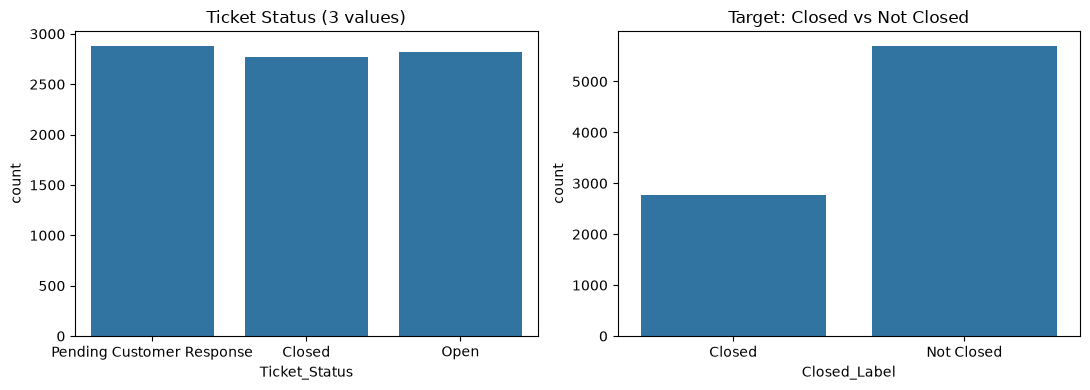

In [20]:
print(df['Ticket_Status'].value_counts())
print()
print(df['Closed_Label'].value_counts())
print((df['Closed_Label'].value_counts(normalize=True) * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='Ticket_Status', data=df, ax=axes[0])
axes[0].set_title('Ticket Status (3 values)')
sns.countplot(x='Closed_Label', data=df, order=['Closed', 'Not Closed'], ax=axes[1])
axes[1].set_title('Target: Closed vs Not Closed')
plt.tight_layout()
plt.show()

Count Plots By Category

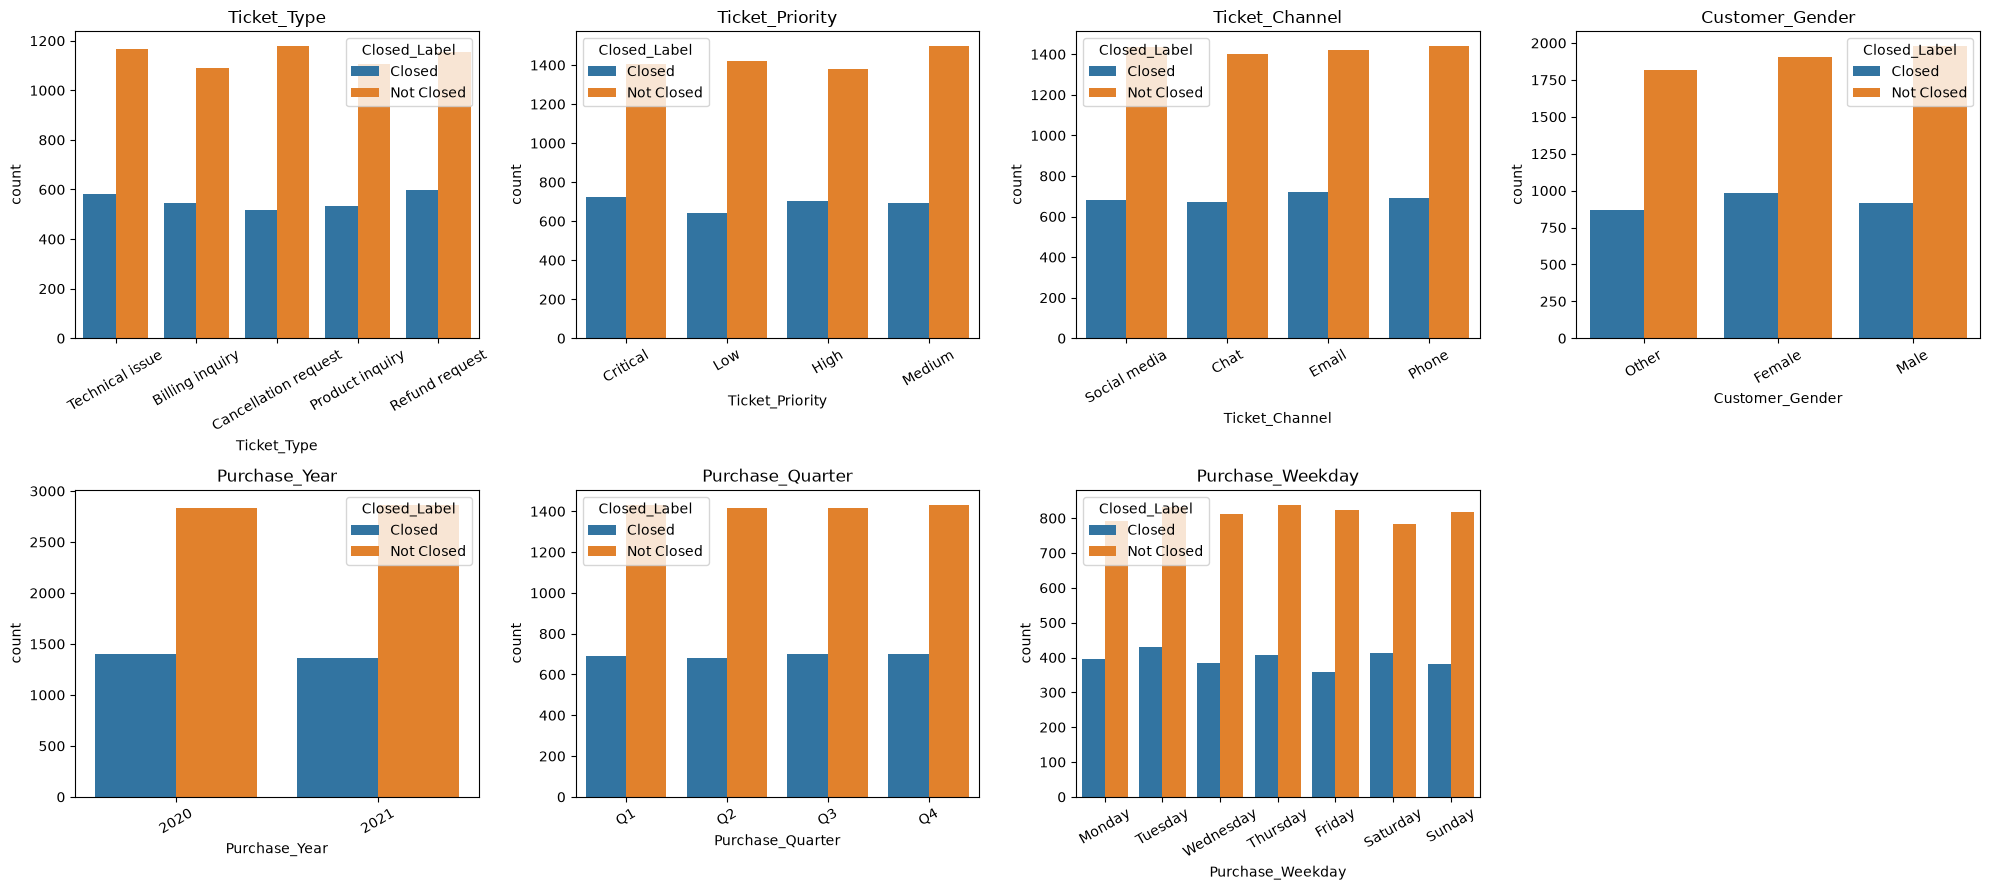

In [21]:
# Leakage rule: no resolution, satisfaction, SLA or first-response columns here
cat_cols = ['Ticket_Type', 'Ticket_Priority', 'Ticket_Channel', 'Customer_Gender',
            'Purchase_Year', 'Purchase_Quarter', 'Purchase_Weekday']

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    sns.countplot(x=col, hue='Closed_Label', hue_order=['Closed', 'Not Closed'], data=df, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=30)
axes[-1].axis('off')   # hide the empty 8th box
plt.tight_layout()
plt.show()

Count Plots: Ticket Subject and Product (many categories)

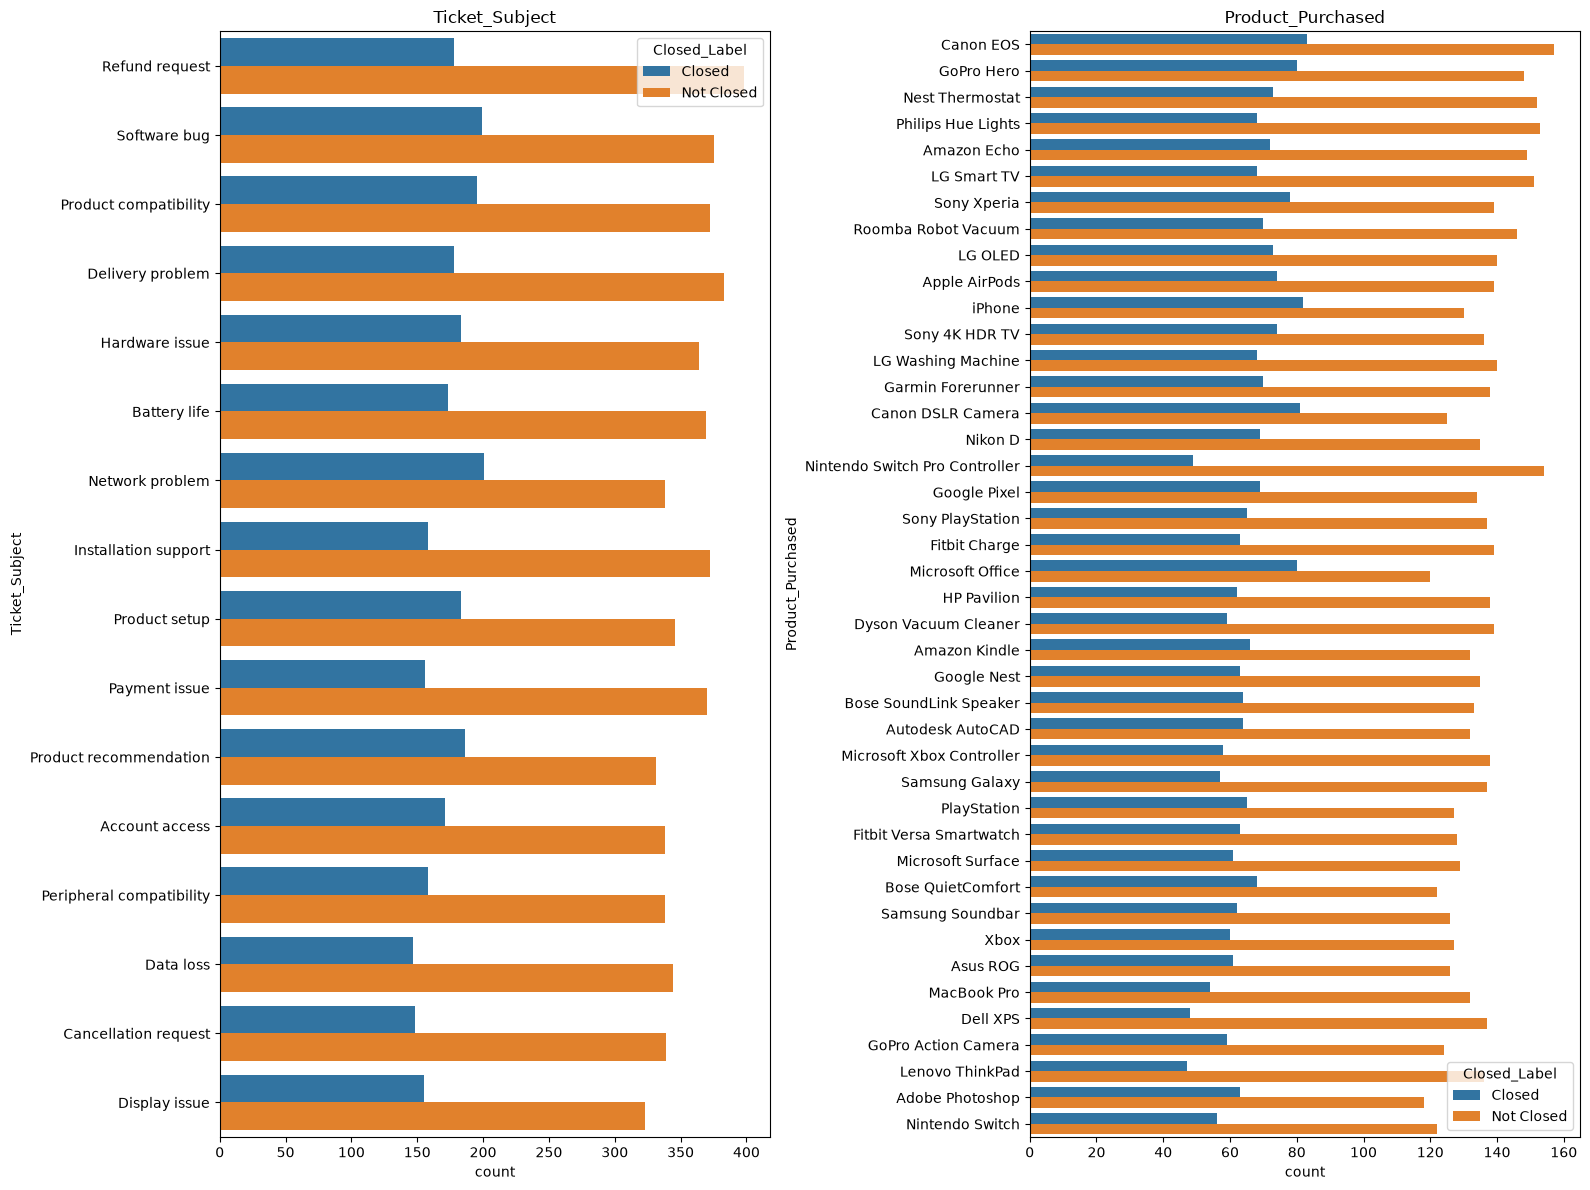

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 12))
for ax, col in zip(axes, ['Ticket_Subject', 'Product_Purchased']):
    order = df[col].value_counts().index
    sns.countplot(y=col, hue='Closed_Label', hue_order=['Closed', 'Not Closed'], data=df, order=order, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Closed rate for each category

In [23]:
overall = df['Closed'].mean() * 100
print(f'Overall Closed rate: {overall:.1f}%\n')

for col in cat_cols:
    print(col, (df.groupby(col, observed=True)['Closed'].mean() * 100).round(1).to_dict())

# Subject (16) and Product (42) have too many values to print in one line: show highest and lowest 5
for col in ['Ticket_Subject', 'Product_Purchased']:
    rate = (df.groupby(col)['Closed'].mean() * 100).round(1).sort_values()
    print(f'\n{col}: lowest 5 -> {rate.head(5).to_dict()}')
    print(f'{col}: highest 5 -> {rate.tail(5).to_dict()}')

Overall Closed rate: 32.7%

Ticket_Type {'Billing inquiry': 33.3, 'Cancellation request': 30.4, 'Product inquiry': 32.5, 'Refund request': 34.0, 'Technical issue': 33.2}
Ticket_Priority {'Critical': 34.1, 'High': 33.8, 'Low': 31.2, 'Medium': 31.7}
Ticket_Channel {'Chat': 32.5, 'Email': 33.6, 'Phone': 32.4, 'Social media': 32.2}
Customer_Gender {'Female': 34.1, 'Male': 31.6, 'Other': 32.4}
Purchase_Year {2020: 33.1, 2021: 32.3}
Purchase_Quarter {'Q1': 32.5, 'Q2': 32.4, 'Q3': 33.0, 'Q4': 32.9}
Purchase_Weekday {'Monday': 33.2, 'Tuesday': 34.1, 'Wednesday': 32.0, 'Thursday': 32.7, 'Friday': 30.4, 'Saturday': 34.6, 'Sunday': 31.7}

Ticket_Subject: lowest 5 -> {'Payment issue': 29.7, 'Installation support': 29.8, 'Data loss': 29.9, 'Cancellation request': 30.4, 'Refund request': 30.9}
Ticket_Subject: highest 5 -> {'Product compatibility': 34.4, 'Product setup': 34.6, 'Software bug': 34.7, 'Product recommendation': 36.0, 'Network problem': 37.3}

Product_Purchased: lowest 5 -> {'Nintendo Swi

Plot Closed rate by category

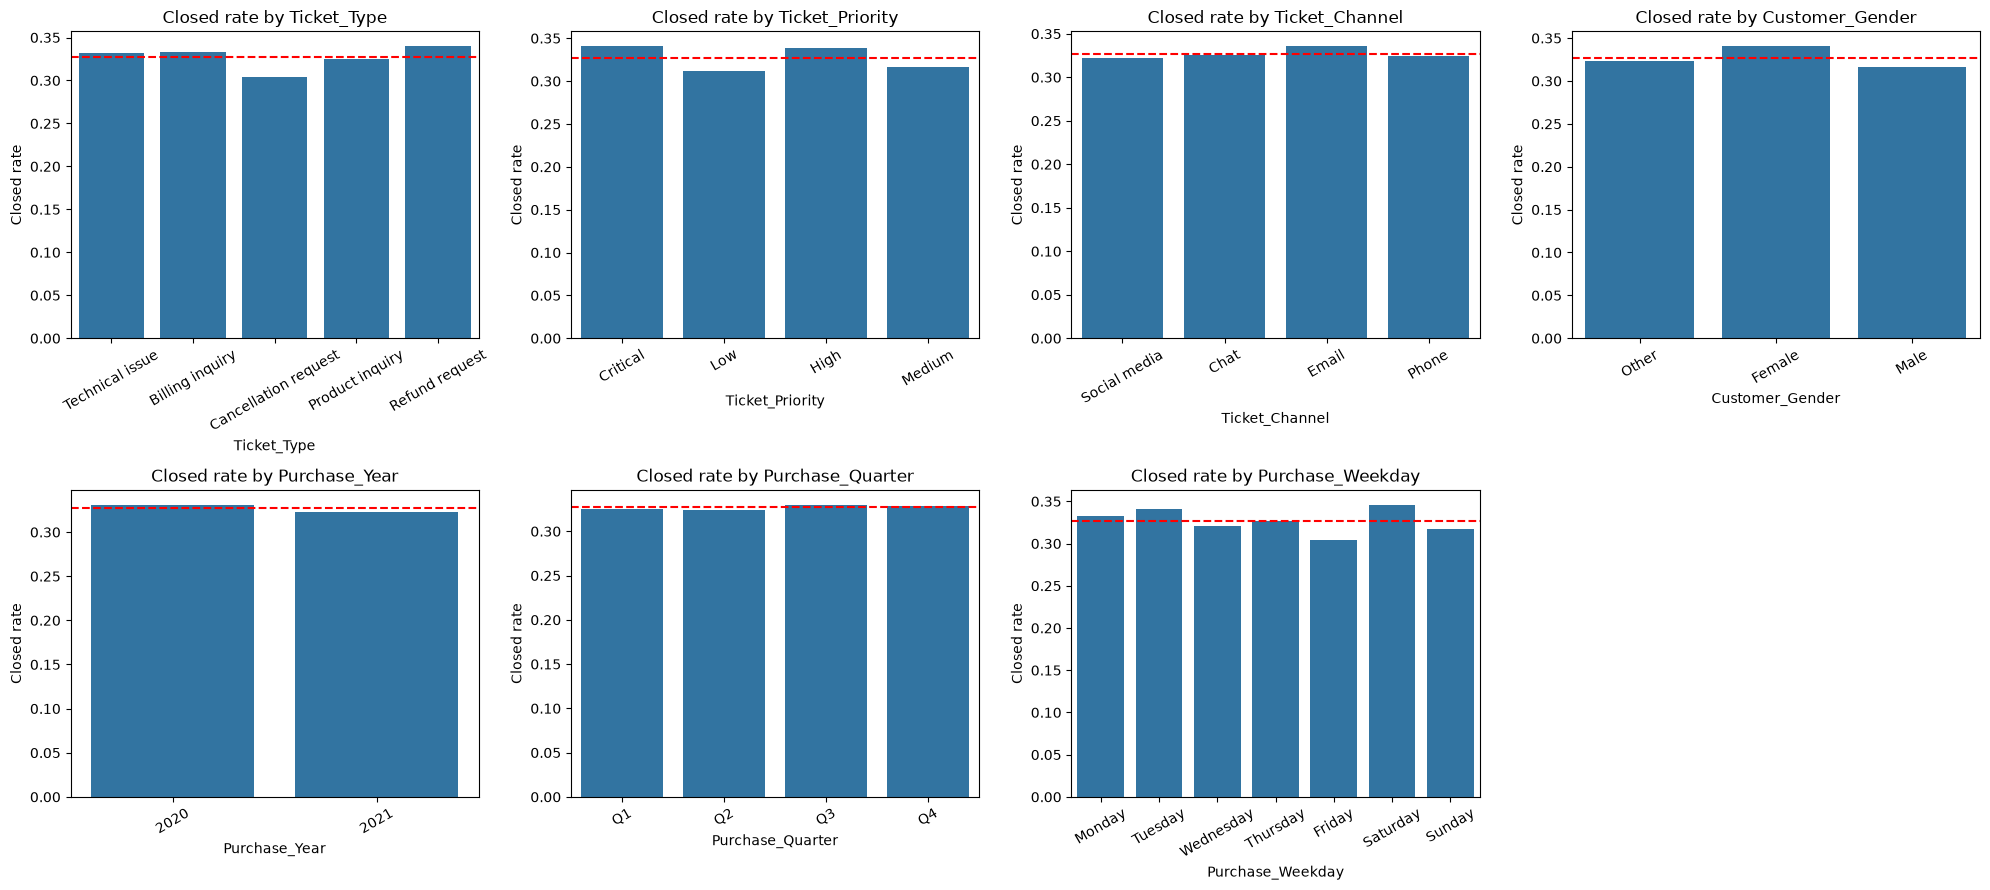

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    sns.barplot(x=col, y='Closed', data=df, errorbar=None, ax=axes[i])
    axes[i].axhline(df['Closed'].mean(), color='red', linestyle='--', label='overall')
    axes[i].set_title('Closed rate by ' + col)
    axes[i].set_ylabel('Closed rate')
    axes[i].tick_params(axis='x', rotation=30)
axes[-1].axis('off')
plt.tight_layout()
plt.show()

Plot Closed rate: Ticket Subject and Product

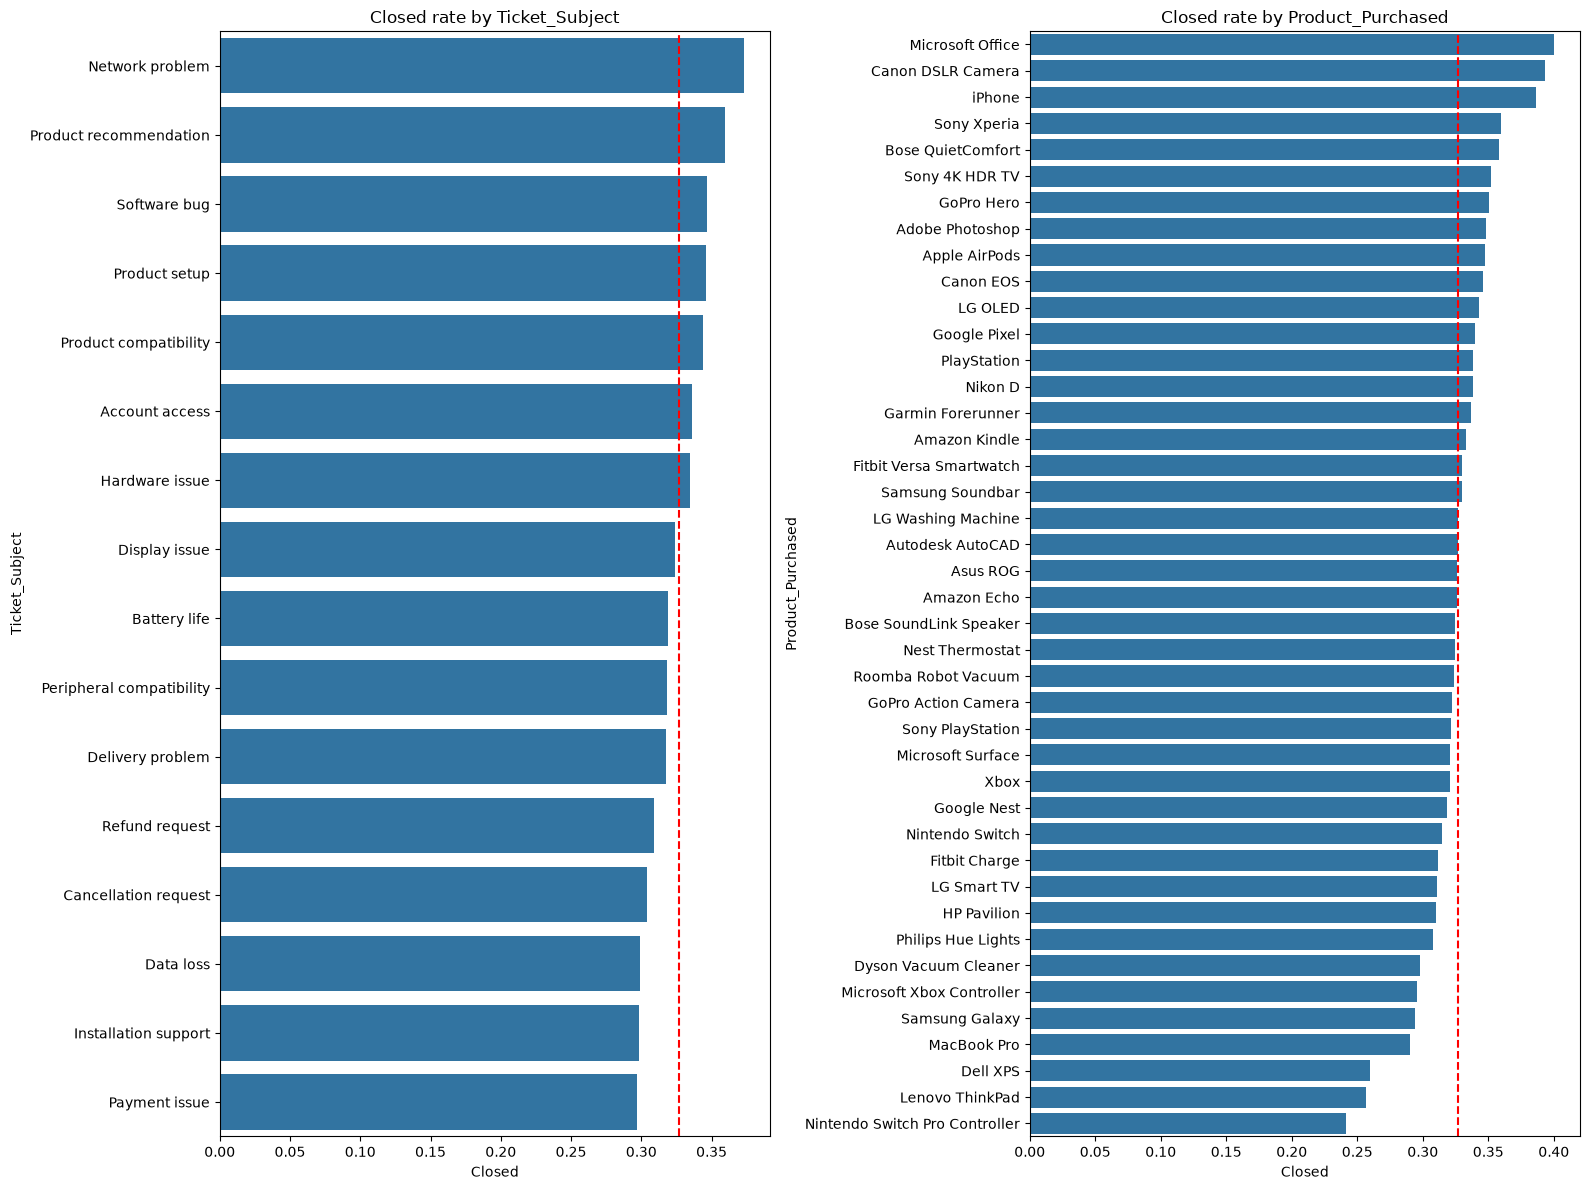

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 12))
for ax, col in zip(axes, ['Ticket_Subject', 'Product_Purchased']):
    order = df.groupby(col)['Closed'].mean().sort_values(ascending=False).index
    sns.barplot(y=col, x='Closed', data=df, order=order, errorbar=None, ax=ax)
    ax.axvline(df['Closed'].mean(), color='red', linestyle='--')
    ax.set_title('Closed rate by ' + col)
plt.tight_layout()
plt.show()

Correlation heatmap

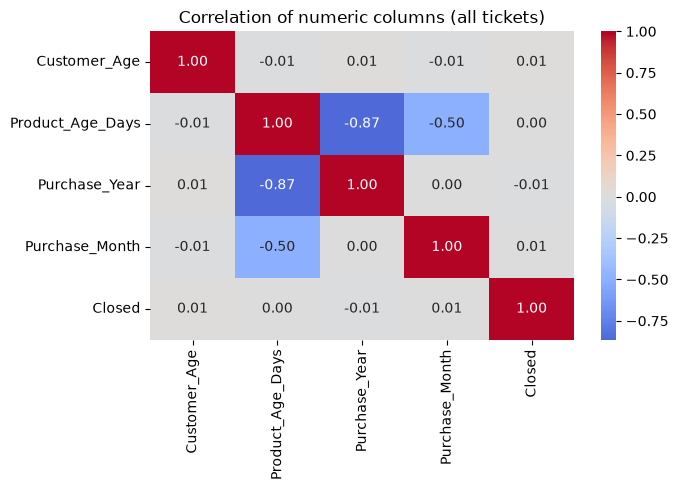

In [26]:
# Only columns known for EVERY ticket (no resolution / satisfaction / response columns)
num_cols = ['Customer_Age', 'Product_Age_Days', 'Purchase_Year', 'Purchase_Month', 'Closed']
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of numeric columns (all tickets)')
plt.tight_layout()
plt.show()

Age and product age bands (quartiles)

In [27]:
for col, band, labels in [
    ('Customer_Age',     'Age_Band',         ['Youngest', 'Younger-Mid', 'Older-Mid', 'Oldest']),
    ('Product_Age_Days', 'Product_Age_Band', ['Newest', 'Newer-Mid', 'Older-Mid', 'Oldest'])]:
    df[band] = pd.qcut(df[col], q=4, labels=labels)
    print(df.groupby(band, observed=True).agg(
        tickets=('Closed', 'count'),
        min_value=(col, 'min'),
        max_value=(col, 'max'),
        closed_rate=('Closed', lambda s: round(s.mean() * 100, 1))), '\n')

             tickets  min_value  max_value  closed_rate
Age_Band                                               
Youngest        2229         18         31         31.1
Younger-Mid     2052         32         44         33.3
Older-Mid       2121         45         57         33.5
Oldest          2067         58         70         33.0 

                  tickets  min_value  max_value  closed_rate
Product_Age_Band                                            
Newest               2124        517        699         32.7
Newer-Mid            2118        700        881         31.7
Older-Mid            2110        882       1063         33.3
Oldest               2117       1064       1246         33.1 



Plot Closed rate by band

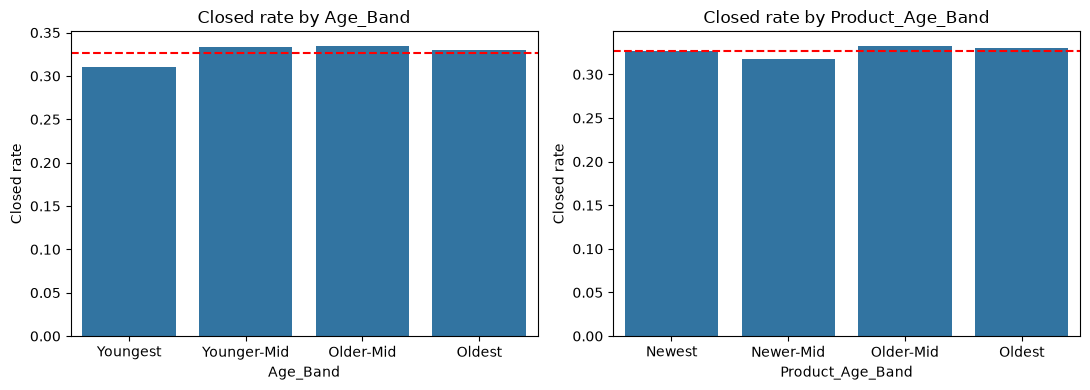

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, band in zip(axes, ['Age_Band', 'Product_Age_Band']):
    sns.barplot(x=band, y='Closed', data=df, errorbar=None, ax=ax)
    ax.axhline(df['Closed'].mean(), color='red', linestyle='--')
    ax.set_title('Closed rate by ' + band)
    ax.set_ylabel('Closed rate')
plt.tight_layout()
plt.show()

Secondary analysis: customer satisfaction (Closed tickets only)

Satisfaction balance

Closed tickets: 2769
Customer_Satisfaction_Rating
1.0    553
2.0    549
3.0    580
4.0    543
5.0    544
Name: count, dtype: int64

Satisfied = rating 4 or 5
Satisfied
Not satisfied    1682
Satisfied        1087
Name: count, dtype: int64
Satisfied rate: 39.3 %


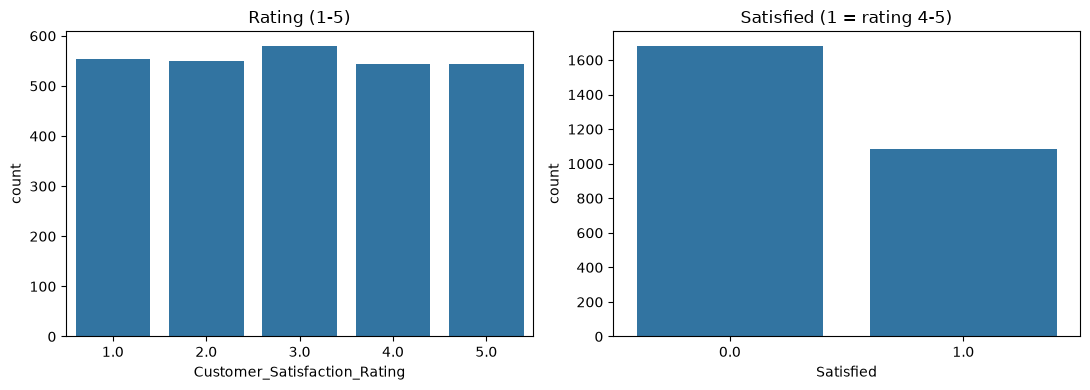

In [29]:
# Only Closed tickets have a rating, so only they are used here
closed_df = df[df['Closed'] == 1].copy()
print('Closed tickets:', len(closed_df))
print(closed_df['Customer_Satisfaction_Rating'].value_counts().sort_index())
print()
print('Satisfied = rating 4 or 5')
print(closed_df['Satisfied'].map({1.0: 'Satisfied', 0.0: 'Not satisfied'}).value_counts())
print('Satisfied rate:', round(closed_df['Satisfied'].mean() * 100, 1), '%')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='Customer_Satisfaction_Rating', data=closed_df, ax=axes[0])
axes[0].set_title('Rating (1-5)')
sns.countplot(x='Satisfied', data=closed_df, ax=axes[1])
axes[1].set_title('Satisfied (1 = rating 4-5)')
plt.tight_layout()
plt.show()

Satisfied rate for each category

Overall Satisfied rate: 39.3%

Ticket_Type {'Billing inquiry': 41.7, 'Cancellation request': 40.1, 'Product inquiry': 39.8, 'Refund request': 37.9, 'Technical issue': 37.1}
Ticket_Priority {'Critical': 38.4, 'High': 39.1, 'Low': 42.5, 'Medium': 37.2}
Ticket_Channel {'Chat': 41.5, 'Email': 39.6, 'Phone': 38.5, 'Social media': 37.4}
Customer_Gender {'Female': 39.9, 'Male': 38.8, 'Other': 39.0}
SLA_Status {'Unknown': 37.7, 'Within SLA': 40.8}
Purchase_Year {2020: 41.6, 2021: 36.8}


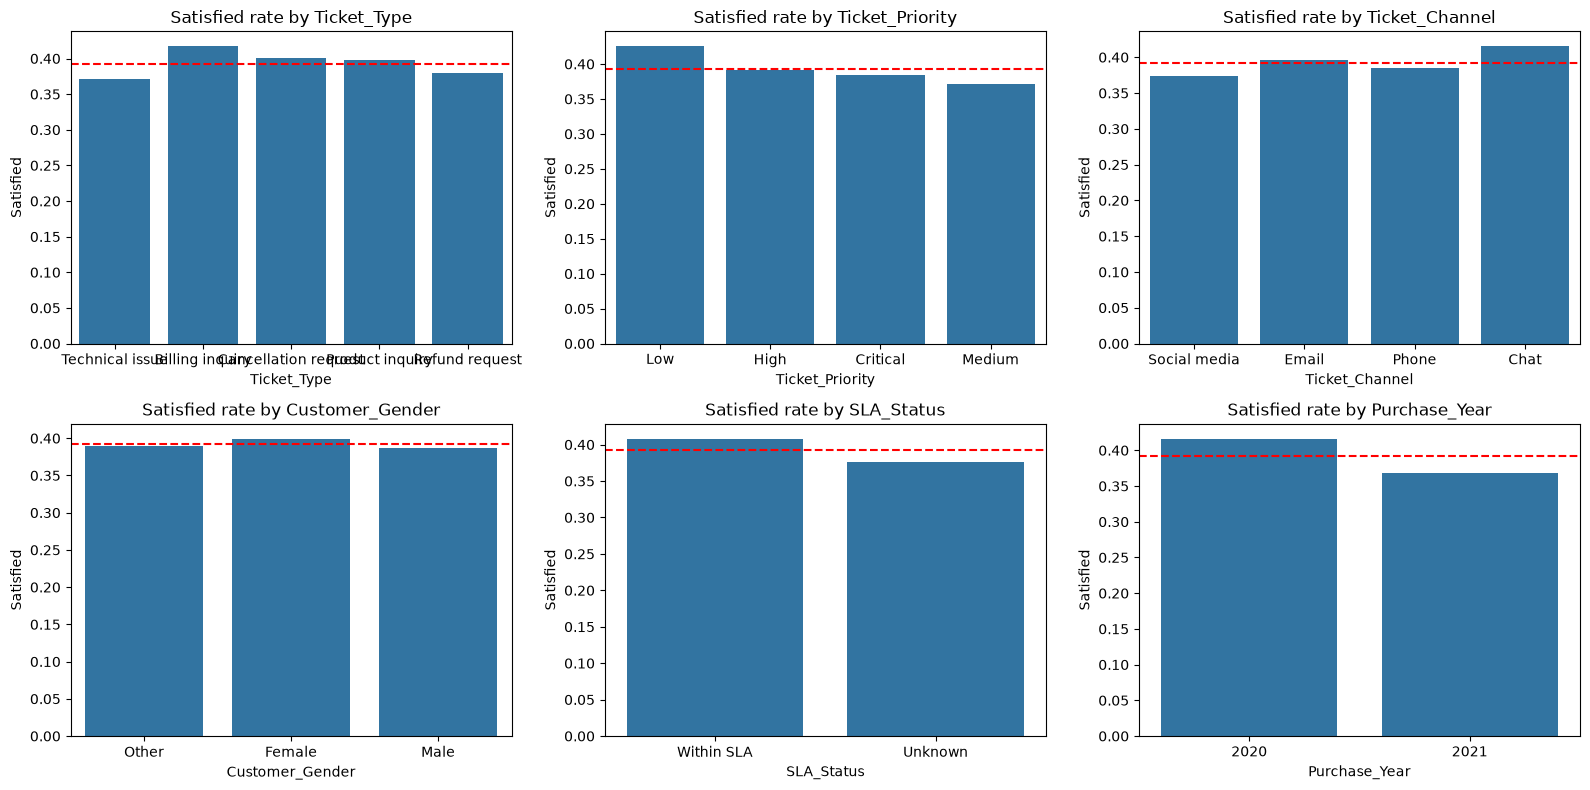

In [30]:
sat_cols = ['Ticket_Type', 'Ticket_Priority', 'Ticket_Channel', 'Customer_Gender', 'SLA_Status', 'Purchase_Year']
print(f'Overall Satisfied rate: {closed_df["Satisfied"].mean() * 100:.1f}%\n')
for col in sat_cols:
    print(col, (closed_df.groupby(col, observed=True)['Satisfied'].mean() * 100).round(1).to_dict())

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for i, col in enumerate(sat_cols):
    sns.barplot(x=col, y='Satisfied', data=closed_df, errorbar=None, ax=axes[i])
    axes[i].axhline(closed_df['Satisfied'].mean(), color='red', linestyle='--')
    axes[i].set_title('Satisfied rate by ' + col)
plt.tight_layout()
plt.show()

Satisfied rate by age band and resolution time band

Closed tickets with a valid resolution time: 1404 of 2769
                 tickets  max_hours  satisfied_rate
Resolution_Band                                    
Fastest              354   3.000000            40.4
Fast-Mid             348   6.316667            39.4
Slow-Mid             351  11.350000            44.4
Slowest              351  23.466667            39.0 



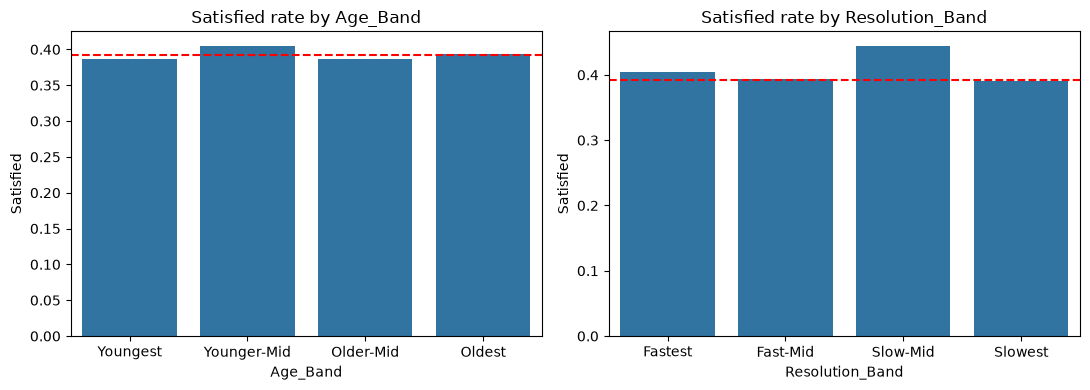

In [31]:
# Resolution bands use only the tickets with a valid duration
valid = closed_df['resolution_hours'].notna()
print('Closed tickets with a valid resolution time:', valid.sum(), 'of', len(closed_df))
closed_df['Resolution_Band'] = pd.qcut(closed_df['resolution_hours'], q=4,
                                       labels=['Fastest', 'Fast-Mid', 'Slow-Mid', 'Slowest'])
print(closed_df.groupby('Resolution_Band', observed=True).agg(
    tickets=('Satisfied', 'count'),
    max_hours=('resolution_hours', 'max'),
    satisfied_rate=('Satisfied', lambda s: round(s.mean() * 100, 1))), '\n')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, band in zip(axes, ['Age_Band', 'Resolution_Band']):
    sns.barplot(x=band, y='Satisfied', data=closed_df, errorbar=None, ax=ax)
    ax.axhline(closed_df['Satisfied'].mean(), color='red', linestyle='--')
    ax.set_title('Satisfied rate by ' + band)
plt.tight_layout()
plt.show()

Correlation heatmap (Closed tickets only)

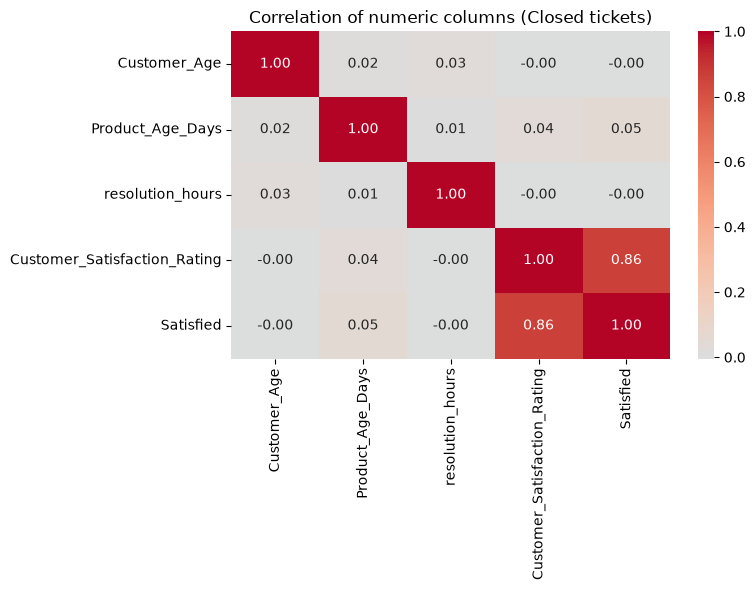

In [32]:
sat_num = ['Customer_Age', 'Product_Age_Days', 'resolution_hours', 'Customer_Satisfaction_Rating', 'Satisfied']
plt.figure(figsize=(8, 6))
sns.heatmap(closed_df[sat_num].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of numeric columns (Closed tickets)')
plt.tight_layout()
plt.show()

Export for Power BI

In [33]:
# Name, email and the free-text description are left out: not needed for the dashboard and they identify people
export_cols = ['Ticket_ID', 'Customer_Age', 'Age_Band', 'Customer_Gender', 'Product_Purchased',
               'Date_of_Purchase', 'Purchase_Year', 'Purchase_Quarter', 'Purchase_Month', 'Purchase_Weekday',
               'Product_Age_Days', 'Product_Age_Band',
               'Ticket_Type', 'Ticket_Subject', 'Ticket_Priority', 'Ticket_Channel',
               'Ticket_Status', 'Closed', 'Closed_Label',
               'Resolution', 'First_Response_Time', 'Time_to_Resolution', 'has_first_response',
               'Response_Hour', 'Response_Weekday',
               'resolution_hours', 'invalid_duration', 'SLA_Status',
               'Customer_Satisfaction_Rating', 'Satisfied']
path = 'ticket_clean.csv'
df[export_cols].to_csv(path, index=False)

check = pd.read_csv(path)
print('Exported shape:', check.shape, '| original rows:', rows_before)
print('\nBlank cells per column (structural gaps, left empty on purpose):')
blank = check.isna().sum()
print(blank[blank > 0])

Exported shape: (8469, 30) | original rows: 8469

Blank cells per column (structural gaps, left empty on purpose):
Resolution                      5700
First_Response_Time             2819
Time_to_Resolution              5700
Response_Hour                   2819
Response_Weekday                2819
resolution_hours                7065
Customer_Satisfaction_Rating    5700
Satisfied                       5700
dtype: int64
